<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/02_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Préparation des données

Ce notebook prépare les images et les masques de segmentation du dataset RoadAnomaly pour entraîner nos modèles de Deep Learning.

## 1. Chargement des données

Nous chargeons les données depuis Google Drive et vérifions que chaque image possède son masque de segmentation correspondant.

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly"
)

frames_dir = dataset_dir / "RoadAnomaly" / "frames"

print("Dataset exists:", dataset_dir.exists())
print("Frames exists:", frames_dir.exists())

Dataset exists: True
Frames exists: True


## 2. Vérification des images et des masques

Nous vérifions les images et leurs annotations :
- 60 images avec des masques sémantiques.
- 46 images avec des masques d'instances.

Les masques sémantiques indiquent les zones anormales, tandis que les masques d'instances permettent de distinguer chaque obstacle.

In [5]:
import pandas as pd

images = sorted(frames_dir.glob("*.webp"))

pairs = []

for image_path in images:
    annotations_dir = frames_dir / f"{image_path.stem}.labels"

    semantic_mask = annotations_dir / "labels_semantic.png"
    instance_mask = annotations_dir / "labels_instance.png"
    instance_json = annotations_dir / "index.json"

    pairs.append({
        "image": str(image_path),
        "mask": str(semantic_mask),
        "instance_mask": str(instance_mask) if instance_mask.exists() else None,
        "instance_json": str(instance_json) if instance_json.exists() else None
    })

df_pairs = pd.DataFrame(pairs)

# Vérification des fichiers
n_semantic = sum(
    (frames_dir / f"{p.stem}.labels" / "labels_semantic.png").exists()
    for p in images
)

n_instance = df_pairs["instance_mask"].notna().sum()

print("Images totales :", len(images))
print("Masques sémantiques :", n_semantic)
print("Masques d'instances :", n_instance)

assert len(images) == n_semantic, "Masques sémantiques manquants"
assert n_instance == df_pairs["instance_json"].notna().sum(), \
    "Annotations d'instances incomplètes"

display(df_pairs.head())

Images totales : 60
Masques sémantiques : 60
Masques d'instances : 46


,image,mask,instance_mask,instance_json
0,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
1,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
2,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
3,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
4,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...


## 3. Séparation des données : entraînement, validation et test

Nous répartissons les 60 images en trois ensembles :

- **Train (70 %, 42 images)** : pour entraîner les modèles.
- **Validation (15 %, 9 images)** : pour suivre les performances et choisir le meilleur modèle.
- **Test (15 %, 9 images)** : pour évaluer les modèles sur des images non utilisées pendant l'entraînement.

Nous utilisons une graine aléatoire fixe (42) et prenons en compte les catégories d'anomalies.

Nous vérifions aussi que des images provenant de la même scène ne se retrouvent pas dans plusieurs ensembles, afin de limiter les fuites de données.

Pour la segmentation d'instances, nous conservons uniquement les 46 images qui possèdent des annotations d'instances, sans changer leur ensemble d'origine.

Cela donne :
- **Train : 33 images**
- **Validation : 5 images**
- **Test : 8 images**

In [6]:
from sklearn.model_selection import train_test_split
import pandas as pd

def get_category(path):
    name = str(path).split("/")[-1].lower()

    for category in ["animals", "obstacles", "cones",
                     "vehicle", "lost_tires"]:
        if name.startswith(category):
            return category

    return "other"

df_pairs["category"] = df_pairs["image"].apply(get_category)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df_pairs,
    test_size=0.30,
    random_state=42,
    stratify=df_pairs["category"]
)

# Second split: 15% validation, 15% testing
# No second stratification because some categories are small
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nCategory distribution:")
display(pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Test": test_df["category"].value_counts()
}).fillna(0).astype(int))

Training images: 42
Validation images: 9
Testing images: 9

Category distribution:


,Train,Validation,Test
category,,,
animals,22,5,4
cones,6,0,2
lost_tires,2,0,1
obstacles,10,4,1
vehicle,2,0,1


In [7]:
train_set = set(train_df["image"])
val_set = set(val_df["image"])
test_set = set(test_df["image"])

assert not train_set & val_set
assert not train_set & test_set
assert not val_set & test_set

assert len(train_set | val_set | test_set) == 60

print("No overlap between image filenames.")
print("Split created successfully!")

No overlap between image filenames.
Split created successfully!


### 3.1. Vérification des risques de fuite de données

**Objectif :** Vérifier que des images provenant d'une même scène ne se retrouvent pas dans plusieurs groupes (entraînement, validation et test).

Nous comparons les noms des images en ignorant les chiffres à la fin pour repérer celles qui pourraient être liées.

**Pourquoi ?** Si le modèle voit des images très similaires pendant l'entraînement et le test, les résultats peuvent être trop optimistes.

Cette vérification permet de repérer les risques de fuite de données, mais ne prouve pas à elle seule que les images montrent la même scène.

In [8]:
import re
from pathlib import Path

def scene_group(path):
    name = Path(path).stem.lower()
    return re.sub(r"\d+$", "", name)

split_data = pd.concat([
    train_df.assign(split="Train"),
    val_df.assign(split="Validation"),
    test_df.assign(split="Test")
])

split_data["scene_group"] = split_data["image"].apply(scene_group)

potential_leakage = (
    split_data.groupby("scene_group")
    .filter(lambda g: len(g) > 1 and g["split"].nunique() > 1)
    .sort_values("scene_group")
)

print("Potentially related images across splits:",
      len(potential_leakage))

display(potential_leakage[
    ["image", "scene_group", "split"]
])

Potentially related images across splits: 7


,image,scene_group,split
40,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Train
41,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Train
39,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Test
54,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
55,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
53,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
56,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Test


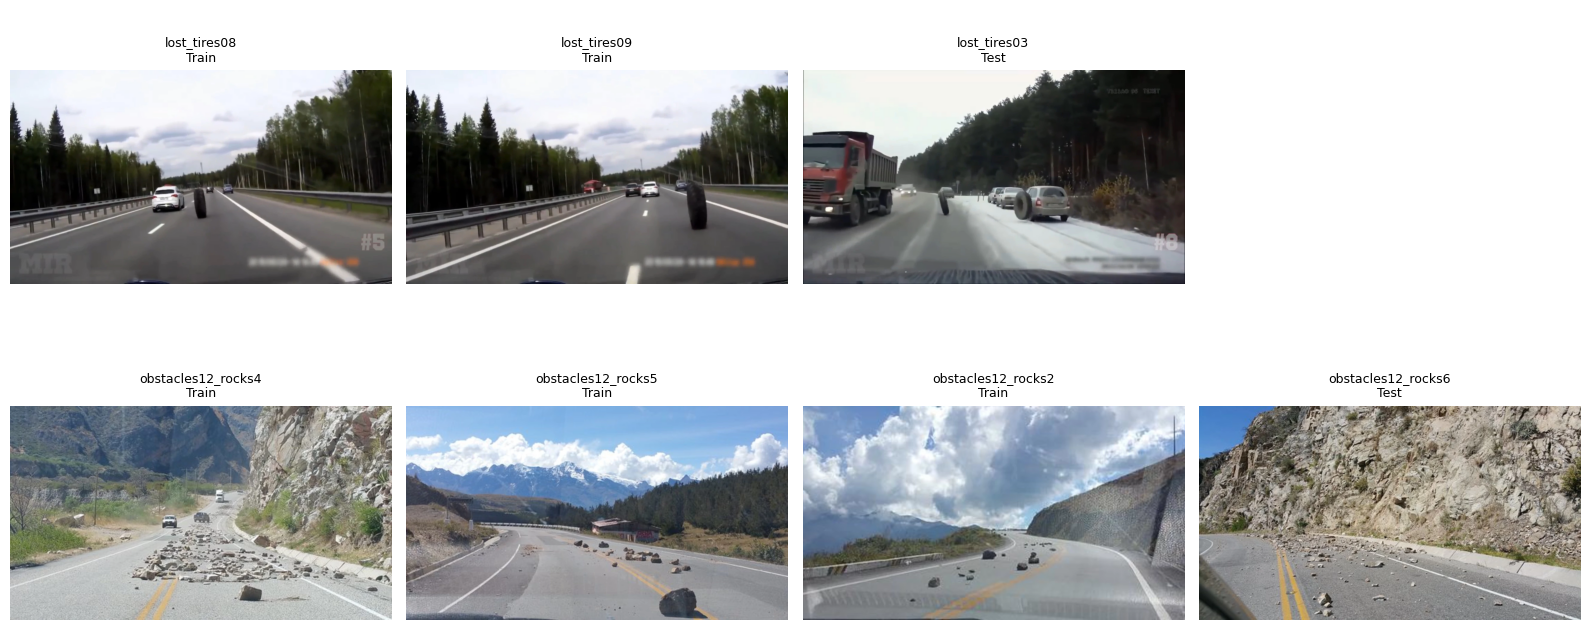

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Display potentially related images
suspected = split_data[
    split_data["scene_group"].isin(["obstacles12_rocks", "lost_tires"])
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax in axes.flat:
    ax.axis("off")

for row, (group, data) in enumerate(suspected.groupby("scene_group")):
    for col, (_, item) in enumerate(data.iterrows()):
        ax = axes[row, col]
        ax.imshow(Image.open(item["image"]).convert("RGB"))
        ax.set_title(f"{Path(item['image']).stem}\n{item['split']}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Move the related rock images into the same split

def is_rock_image(path):
    return Path(path).stem.startswith("obstacles12_rocks")

rock_test = test_df[test_df["image"].apply(is_rock_image)]

replacement = train_df[
    (train_df["category"] == "obstacles")
    & (~train_df["image"].apply(is_rock_image))
]

assert len(rock_test) == 1
assert len(replacement) > 0, "No suitable replacement found"

rock = rock_test.iloc[[0]]
other = replacement.iloc[[0]]

train_df = pd.concat([
    train_df.drop(other.index), rock
]).reset_index(drop=True)

test_df = pd.concat([
    test_df.drop(rock.index), other
]).reset_index(drop=True)

# Verify the corrected split
assert (len(train_df), len(val_df), len(test_df)) == (42, 9, 9)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Rock images in training:",
      train_df["image"].apply(is_rock_image).sum())
print("Rock images in testing:",
      test_df["image"].apply(is_rock_image).sum())

Train: 42
Validation: 9
Test: 9
Rock images in training: 4
Rock images in testing: 0


### 3.2. Vérification de la répartition finale

Nous avons vérifié les noms et les images pour éviter que des photos d'une même scène se retrouvent dans plusieurs groupes. Cela pourrait fausser les résultats du modèle.

- **Images avec des rochers :** Nous avons regroupé les images similaires dans l'ensemble d'entraînement.
- **Images avec des pneus :** Après vérification, aucun changement n'était nécessaire.

La répartition finale reste :
- **Entraînement :** 42 images
- **Validation :** 9 images
- **Test :** 9 images

Cette répartition sera sauvegardée pour utiliser les mêmes images lors de l'entraînement et de l'évaluation des différents modèles.

In [18]:
# Sauvegarder la répartition finale corrigée
final_split = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

# Sauvegarder le même split pour les deux tâches
split_path = Path(
    "/content/drive/MyDrive/deep learning P/split_manifest.csv"
)

final_split.to_csv(split_path, index=False)

# Répartition des 60 images
print("Segmentation sémantique :")
print(final_split["split"].value_counts())

# Répartition des 46 images avec annotations d'instances
instance_split = final_split[
    final_split["instance_mask"].notna()
].copy()

print("\nSegmentation d'instances :")
print(instance_split["split"].value_counts())

# Vérifications
assert len(final_split) == 60
assert len(instance_split) == 46

assert final_split["split"].value_counts().to_dict() == {
    "train": 42, "validation": 9, "test": 9
}

assert instance_split["split"].value_counts().to_dict() == {
    "train": 33, "validation": 5, "test": 8
}

print("\nFichier sauvegardé :", split_path)

Segmentation sémantique :
split
train         42
validation     9
test           9
Name: count, dtype: int64

Segmentation d'instances :
split
train         33
test           8
validation     5
Name: count, dtype: int64

Fichier sauvegardé : /content/drive/MyDrive/deep learning P/split_manifest.csv


## 4. Prétraitement des images

Nous préparons les images et leurs masques pour entraîner nos modèles de Deep Learning.

### Méthodes utilisées

- **Redimensionnement avec padding (256 × 256) :** Nous réduisons les images en gardant leurs proportions, puis nous ajoutons des bandes noires pour obtenir une taille fixe. Cela évite de déformer les obstacles.
- **Normalisation (0 à 1) :** Nous transformons les valeurs des pixels entre 0 et 1 pour faciliter l'apprentissage.
- **Masques binaires :** Nous utilisons deux classes : 0 pour les zones normales et 1 pour les anomalies.
- **Interpolation :** Nous utilisons l'interpolation bilinéaire pour les images et le plus proche voisin pour les masques afin de conserver les étiquettes.

**Remarque :** Les fichiers originaux ne sont pas modifiés.

In [12]:
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = (256, 256)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    # Resize without distortion and add padding
    image = ImageOps.pad(
        image,
        IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )

    # Normalize between 0 and 1
    return np.asarray(image, dtype=np.float32) / 255.0


def preprocess_mask(mask_path):
    mask = Image.open(mask_path).convert("L")

    # Apply the same resizing and padding to the mask
    mask = ImageOps.pad(
        mask,
        IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )

    # Convert anomaly label 2 into 1
    return (np.asarray(mask) == 2).astype(np.float32)

## 4. Prétraitement des images et des masques

Nous préparons les images et les deux types de masques pour nos modèles de Deep Learning.

- **Resize :** 256 × 256 avec padding pour conserver les proportions.
- **Normalization :** valeurs RGB entre 0 et 1.
- **Masques sémantiques :** transformation des labels 0 et 2 en 0 et 1.
- **Masques d'instances :** conservation des identifiants de chaque obstacle.
- **Interpolation :** bilinéaire pour les images et nearest neighbor pour les masques.

Les fichiers originaux ne sont pas modifiés.

In [22]:
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = (256, 256)

# Prétraitement des images (commun aux deux tâches)
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = ImageOps.pad(
        image,
        IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )

    return np.asarray(image, dtype=np.float32) / 255.0


# Redimensionnement commun aux deux types de masques
def resize_mask(mask_path):
    mask = Image.open(mask_path)

    mask = ImageOps.pad(
        mask,
        IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )

    return np.asarray(mask)


# Masque sémantique : 0 = normal, 1 = anomalie
def preprocess_mask(mask_path):
    mask = resize_mask(mask_path)

    return (mask == 2).astype(np.float32)


# Masque d'instances : conserver les identifiants
def preprocess_instance_mask(mask_path):
    return resize_mask(mask_path)

sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
semantic_mask = preprocess_mask(sample["mask"])

print("Image :", image.shape)
print("Masque sémantique :", semantic_mask.shape)
print("Valeurs des pixels :", image.min(), image.max())
print("Labels sémantiques :", np.unique(semantic_mask))

# Vérification des instances sur une image annotée
instance_sample = final_split[
    final_split["instance_mask"].notna()
].iloc[0]

instance_mask = preprocess_instance_mask(
    instance_sample["instance_mask"]
)

print("Masque d'instances :", instance_mask.shape)
print("Identifiants d'instances :", np.unique(instance_mask))

Image : (256, 256, 3)
Masque sémantique : (256, 256)
Valeurs des pixels : 0.0 1.0
Labels sémantiques : [0. 1.]
Masque d'instances : (256, 256)
Identifiants d'instances : [0 1 2 3 4]


## 5. Transformation des labels

Nous préparons les annotations selon le type de segmentation :

- **Segmentation sémantique :** les labels originaux 0 et 2 deviennent 0 (normal) et 1 (anomalie).
- **Segmentation d'instances :** chaque obstacle possède un identifiant différent. Nous créons un masque binaire pour chaque obstacle et lui attribuons le label 1 (anomalie).

Nous utilisons les 60 masques sémantiques et les 46 masques d'instances contenant 201 obstacles annotés.

In [24]:
# Transformer un masque d'instances en masques individuels
def extract_instance_masks(mask_path):
    mask = preprocess_instance_mask(mask_path)

    # Identifiants des obstacles, sans le fond (0)
    ids = np.unique(mask)
    ids = ids[ids != 0]

    # Un masque binaire par obstacle
    masks = np.stack([
        (mask == obj_id).astype(np.uint8)
        for obj_id in ids
    ]) if len(ids) else np.zeros((0, 256, 256), dtype=np.uint8)

    # Tous les obstacles appartiennent à la classe anomalie
    labels = np.ones(len(ids), dtype=np.int64)

    return masks, labels


# Vérification sur une image annotée
sample = final_split[
    final_split["instance_mask"].notna()
].iloc[0]

semantic_mask = preprocess_mask(sample["mask"])
instance_masks, labels = extract_instance_masks(
    sample["instance_mask"]
)

print("Labels sémantiques :", np.unique(semantic_mask))
print("Nombre d'obstacles :", len(labels))
print("Dimensions des masques individuels :", instance_masks.shape)
print("Labels des obstacles :", labels)

Labels sémantiques : [0. 1.]
Nombre d'obstacles : 4
Dimensions des masques individuels : (4, 256, 256)
Labels des obstacles : [1 1 1 1]


## 6. Création des bounding boxes

Pour chaque obstacle, nous calculons une bounding box : un rectangle qui indique sa position dans l'image.

Chaque rectangle est défini par quatre coordonnées : `(xmin, ymin, xmax, ymax)`.

Ces informations sont nécessaires pour entraîner Mask R-CNN.

In [25]:
import numpy as np

def create_bounding_boxes(instance_masks):
    boxes = []

    for mask in instance_masks:
        ys, xs = np.where(mask == 1)

        xmin = xs.min()
        ymin = ys.min()
        xmax = xs.max() + 1
        ymax = ys.max() + 1

        boxes.append([xmin, ymin, xmax, ymax])

    return np.array(boxes, dtype=np.float32).reshape(-1, 4)


# Vérification sur les 4 obstacles de notre exemple
boxes = create_bounding_boxes(instance_masks)

print("Nombre de bounding boxes :", len(boxes))
print("Dimensions :", boxes.shape)
print("Coordonnées :")
print(boxes)

Nombre de bounding boxes : 4
Dimensions : (4, 4)
Coordonnées :
[[198. 152. 243. 186.]
 [116. 143. 192. 180.]
 [ 57. 146.  75. 166.]
 [ 31. 140.  60. 163.]]


## 7. Augmentation des données

Pour limiter le surapprentissage, nous appliquons trois transformations :

- **Retournement horizontal :** appliqué à l'image et au masque ensemble.
- **Luminosité :** rend les images plus claires ou plus sombres.
- **Contraste :** modifie la différence entre les zones claires et sombres.

La même fonction est utilisée pour les masques sémantiques et les masques d'instances. Elle conserve les valeurs des labels.

L'augmentation est appliquée uniquement aux données d'entraînement, sans modifier les fichiers originaux.

In [23]:
import numpy as np

rng = np.random.default_rng(42)

def augment_image_mask(image, mask, rng):
    image = image.copy()
    mask = mask.copy()

    # Retournement horizontal
    if rng.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    # Variation de luminosité
    brightness = rng.uniform(0.8, 1.2)
    image = np.clip(image * brightness, 0, 1)

    # Variation de contraste
    contrast = rng.uniform(0.8, 1.2)
    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip((image - mean) * contrast + mean, 0, 1)

    return image.astype(np.float32), mask

print("Fonction d'augmentation prête pour les deux types de masques.")

Fonction d'augmentation prête pour les deux types de masques.


###  Visualisation de l'augmentation des données

Cette partie sert uniquement à visualiser les transformations appliquées aux images d'entraînement.

Nous affichons plusieurs versions d'une même image :

- **Image originale :** Sans modification.
- **Retournement horizontal :** Image inversée de gauche à droite.
- **Luminosité augmentée :** Image plus claire.
- **Luminosité diminuée :** Image plus sombre.
- **Contraste augmenté :** Différence plus marquée entre les zones claires et sombres.

**Remarque :** Pour les images de routes, le retournement horizontal est adapté. En revanche, le retournement vertical et les grandes rotations ne sont pas utilisés, car ils produisent des scènes peu réalistes.

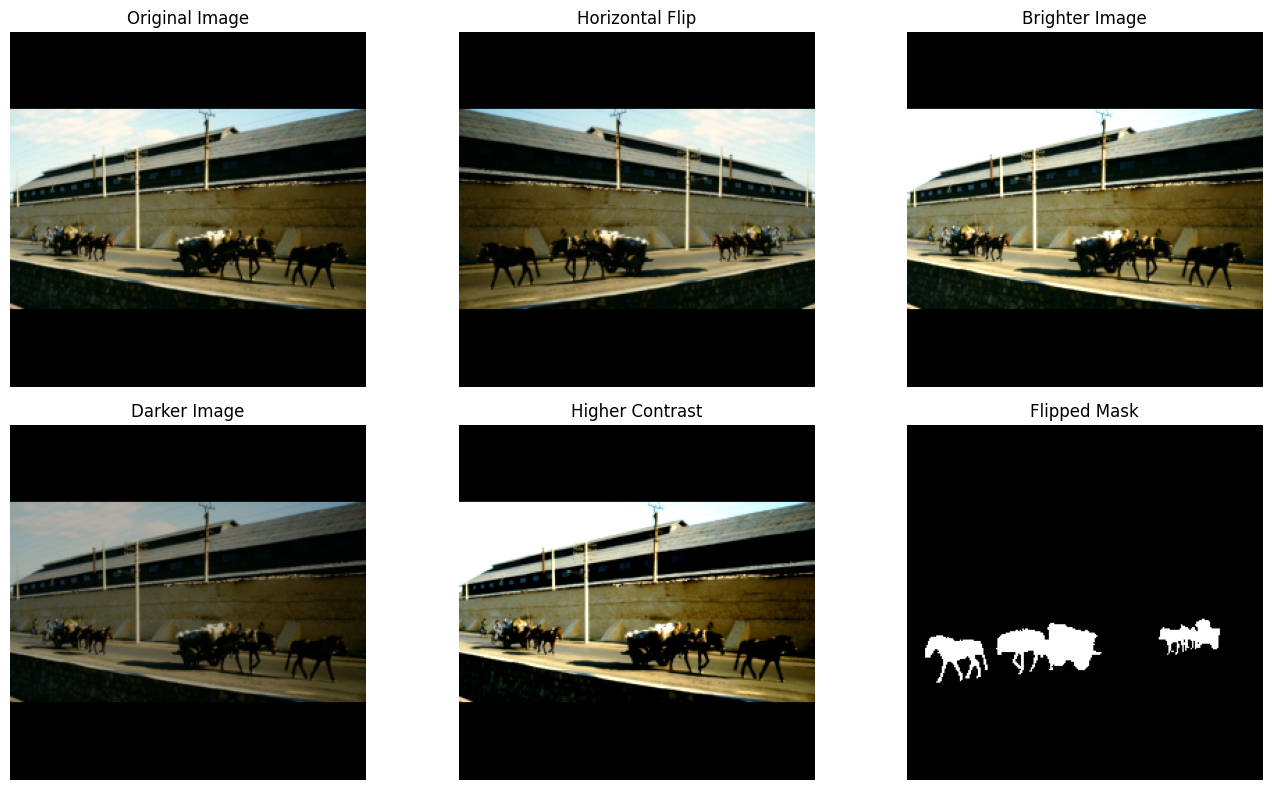

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Select one training example
sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
mask = preprocess_mask(sample["mask"])

# Variants for visualization only
original = image.copy()
flipped = np.fliplr(image).copy()
flipped_mask = np.fliplr(mask).copy()

brighter = np.clip(image * 1.3, 0, 1)
darker = np.clip(image * 0.7, 0, 1)

mean = image.mean(axis=(0, 1), keepdims=True)
higher_contrast = np.clip((image - mean) * 1.4 + mean, 0, 1)

# Show image variants
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(flipped)
axes[0, 1].set_title("Horizontal Flip")

axes[0, 2].imshow(brighter)
axes[0, 2].set_title("Brighter Image")

axes[1, 0].imshow(darker)
axes[1, 0].set_title("Darker Image")

axes[1, 1].imshow(higher_contrast)
axes[1, 1].set_title("Higher Contrast")

axes[1, 2].imshow(flipped_mask, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Flipped Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Dataset et DataLoader avec PyTorch

Nous préparons les données pour les deux types de segmentation :

- **Segmentation sémantique :** 60 images et leurs masques binaires, avec un batch size de 4.
- **Segmentation d'instances :** 46 images et 201 obstacles annotés, avec un batch size de 2.

Pour Mask R-CNN, chaque image contient ses masques individuels, ses labels et ses bounding boxes.

L'augmentation est appliquée uniquement au Train. La Validation et le Test restent sans augmentation.

In [16]:
import torch
from torch.utils.data import Dataset, DataLoader

class RoadAnomalyDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(
                image, mask, self.rng
            )

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask


# Create datasets
train_dataset = RoadAnomalyDataset(train_df, augment=True)
val_dataset = RoadAnomalyDataset(val_df, augment=False)
test_dataset = RoadAnomalyDataset(test_df, augment=False)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=0
)

# Verify one batch
images_batch, masks_batch = next(iter(train_loader))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print("Image batch shape:", images_batch.shape)
print("Mask batch shape:", masks_batch.shape)

assert images_batch.shape == (4, 3, 256, 256)
assert masks_batch.shape == (4, 1, 256, 256)
assert set(torch.unique(masks_batch).tolist()).issubset({0.0, 1.0})

print("DataLoaders ready for U-Net!")

Training samples: 42
Validation samples: 9
Testing samples: 9
Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])
DataLoaders ready for U-Net!


In [26]:
# Dataset pour Mask R-CNN
class RoadAnomalyInstanceDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_instance_mask(row["instance_mask"])

        if self.augment:
            image, mask = augment_image_mask(image, mask, self.rng)

        # Un masque par obstacle
        ids = np.unique(mask)
        ids = ids[ids != 0]

        masks = np.stack([
            (mask == obj_id).astype(np.uint8)
            for obj_id in ids
        ]) if len(ids) else np.zeros((0, 256, 256), dtype=np.uint8)

        labels = np.ones(len(ids), dtype=np.int64)
        boxes = create_bounding_boxes(masks)

        # Conversion en tenseurs
        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        boxes = torch.tensor(boxes, dtype=torch.float32)

        target = {
            "boxes": boxes,
            "labels": torch.tensor(labels, dtype=torch.int64),
            "masks": torch.from_numpy(masks.copy()),
            "image_id": torch.tensor(idx),
            "iscrowd": torch.zeros(len(ids), dtype=torch.int64),
            "area": (
                (boxes[:, 2] - boxes[:, 0])
                * (boxes[:, 3] - boxes[:, 1])
            )
        }

        return image, target


# Sélection des 46 images avec annotations d'instances
instance_train_df = train_df[train_df["instance_mask"].notna()]
instance_val_df = val_df[val_df["instance_mask"].notna()]
instance_test_df = test_df[test_df["instance_mask"].notna()]

# Création des Datasets
instance_train_dataset = RoadAnomalyInstanceDataset(
    instance_train_df, augment=True
)
instance_val_dataset = RoadAnomalyInstanceDataset(
    instance_val_df, augment=False
)
instance_test_dataset = RoadAnomalyInstanceDataset(
    instance_test_df, augment=False
)

# Fonction pour regrouper les données de Mask R-CNN
def collate_fn(batch):
    return tuple(zip(*batch))

# Création des DataLoaders
instance_train_loader = DataLoader(
    instance_train_dataset, batch_size=2,
    shuffle=True, collate_fn=collate_fn
)

instance_val_loader = DataLoader(
    instance_val_dataset, batch_size=2,
    shuffle=False, collate_fn=collate_fn
)

instance_test_loader = DataLoader(
    instance_test_dataset, batch_size=2,
    shuffle=False, collate_fn=collate_fn
)

# Résumé
print("Segmentation sémantique :",
      len(train_dataset), len(val_dataset), len(test_dataset))

print("Segmentation d'instances :",
      len(instance_train_dataset),
      len(instance_val_dataset),
      len(instance_test_dataset))

images_batch, targets_batch = next(iter(instance_train_loader))

print("Images dans le batch :", len(images_batch))
print("Image :", images_batch[0].shape)
print("Masques :", targets_batch[0]["masks"].shape)
print("Boxes :", targets_batch[0]["boxes"].shape)

Segmentation sémantique : 42 9 9
Segmentation d'instances : 33 5 8
Images dans le batch : 2
Image : torch.Size([3, 256, 256])
Masques : torch.Size([1, 256, 256])
Boxes : torch.Size([1, 4])


In [27]:
# Final verification of all three datasets

for name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    total = 0

    for imgs, masks in loader:
        assert imgs.ndim == 4 and imgs.shape[1:] == (3, 256, 256)
        assert masks.ndim == 4 and masks.shape[1:] == (1, 256, 256)
        assert torch.isfinite(imgs).all()
        assert torch.isfinite(masks).all()
        assert imgs.min() >= 0 and imgs.max() <= 1
        assert torch.all((masks == 0) | (masks == 1))
        total += len(imgs)

    assert total == len(loader.dataset)
    print(f"{name}: {total} samples verified")

# Check that no image appears in multiple splits
train_paths = set(train_df["image"])
val_paths = set(val_df["image"])
test_paths = set(test_df["image"])

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

print("No duplicate image paths across splits.")
print("Data Preparation verification passed!")

Train: 42 samples verified
Validation: 9 samples verified
Test: 9 samples verified
No duplicate image paths across splits.
Data Preparation verification passed!
